<a href="https://colab.research.google.com/github/Zinc-zn/MachineLearning2026/blob/main/JS08/JS08_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# JS08 - Hierarchical Clustering: Lab 2 (HDBSCAN)

Praktikum mempelajari algoritma **HDBSCAN (Hierarchical Density-Based Spatial Clustering of Applications with Noise)** sebagai metode clustering berbasis densitas yang lebih robust dibandingkan DBSCAN: mampu mengatasi keterbatasan parameter `eps` yang sensitif serta menyesuaikan diri dengan data yang memiliki kepadatan berbeda (*multiscale*).

Fokus: eksplorasi hasil clustering dataset sintetis serta pengaruh hyperparameter penting seperti `min_cluster_size`, `min_samples`, dan `cut_distance`.


## Langkah 0 - Persiapan Lingkungan

Modul `hdbscan` tidak tersedia default di scikit-learn. Pada modul tertulis `!pip install hdbscan` (untuk Google Colab); pada venv lokal notebook ini **hdbscan sudah terinstal** (`pip install hdbscan` saat setup).

In [1]:
# Instalasi library hdbscan (jika belum ada):
#   !pip install hdbscan     <- untuk Google Colab
#   hdbscan sudah terinstal pada .venv lokal folder JS08

# Import modul
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import hdbscan

## Langkah 1 - Membuat Fungsi Visualisasi

Fungsi ini digunakan untuk plotting hasil clustering dengan warna berbeda; noise ditandai simbol `x` berwarna hitam, sedangkan ukuran titik sebanding dengan *membership strength* (probabilitas) titik tersebut pada clusternya.

In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

## Langkah 3 - Membuat Data Sintetis

Dataset terdiri dari 3 buah cluster Gaussian dengan standar deviasi berbeda-beda.

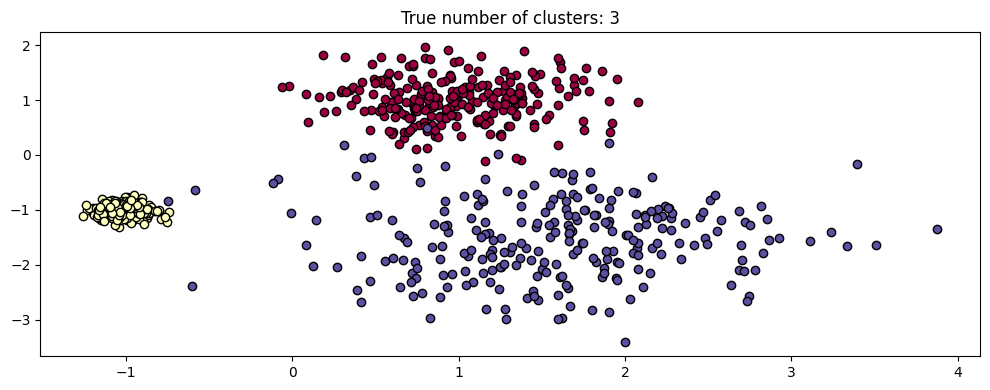

In [3]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)

## Langkah 4 - Uji Scale Invariance Pada Model DBSCAN

Jalankan DBSCAN dengan `eps=0.3` pada dataset yang di-*scale* (dikali 1, 0.5, dan 3).

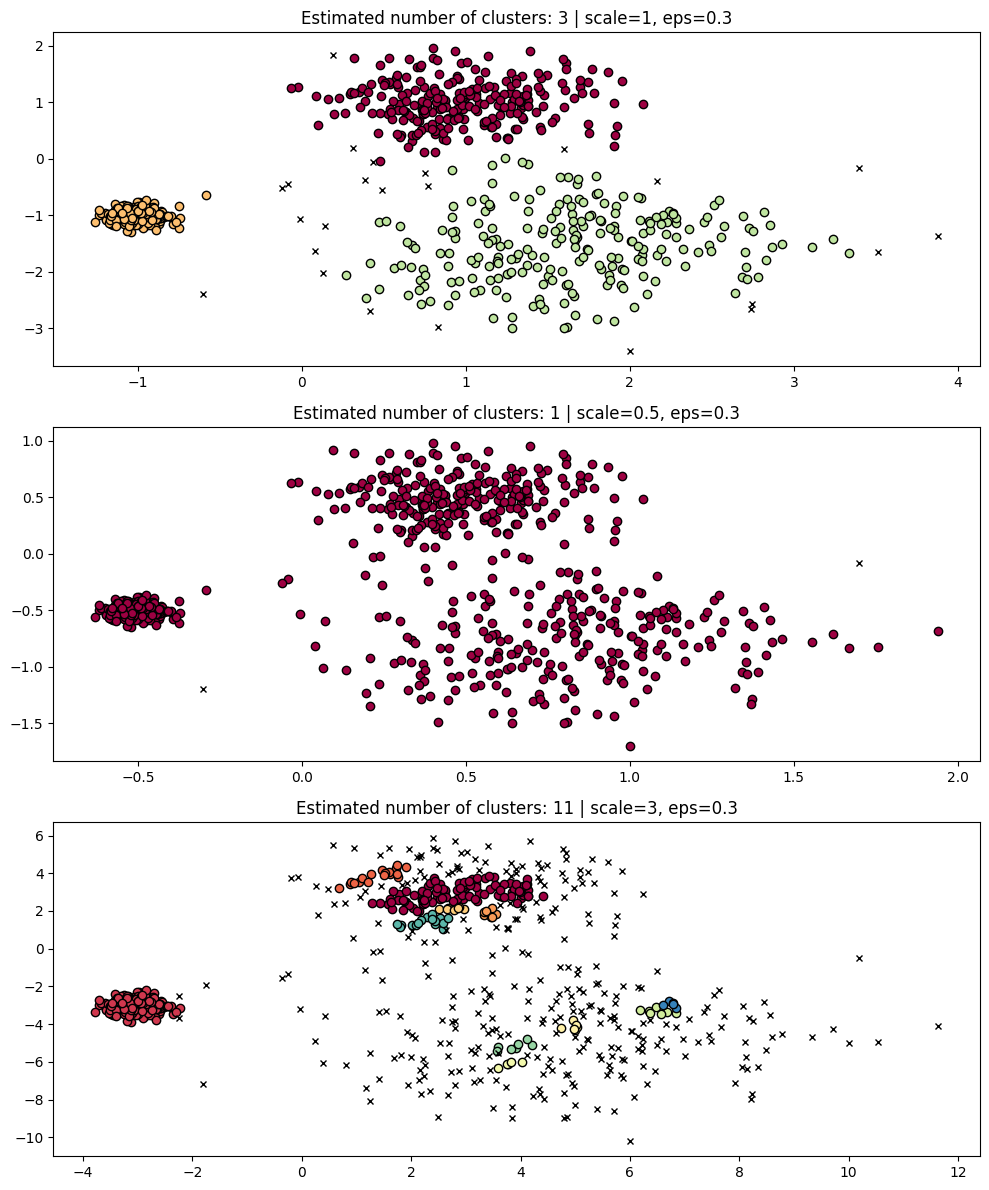

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])

DBSCAN **tidak invarian terhadap skala**: jumlah cluster yang terdeteksi berubah-ubah ketika data diskalakan (pada scale=0.5 cluster bergabung, pada scale=3 data menjadi terlalu renggang sehingga banyak noise). Perbaiki dengan mengubah `eps` sesuai skala:

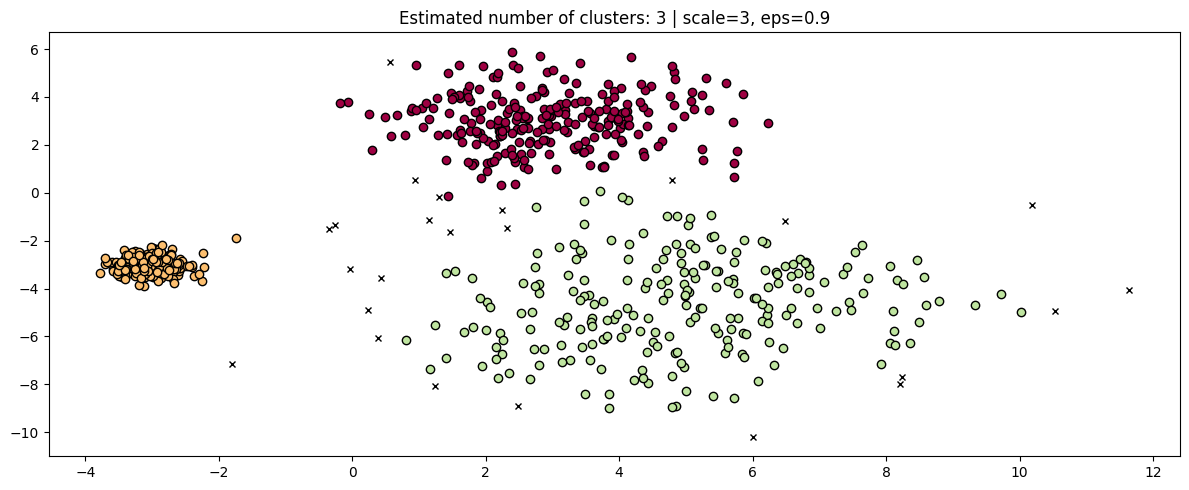

In [5]:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)

Dengan menyesuaikan `eps` (0.3 → 0.9), DBSCAN kembali menemukan 3 cluster pada data scale=3. Artinya, pengguna DBSCAN **harus menyetel ulang `eps` setiap kali skala data berubah**.

## Langkah 5 - Membuat Model HDBSCAN

Jalankan HDBSCAN pada dataset berskala berbeda untuk mengetahui perbedaannya dengan DBSCAN.

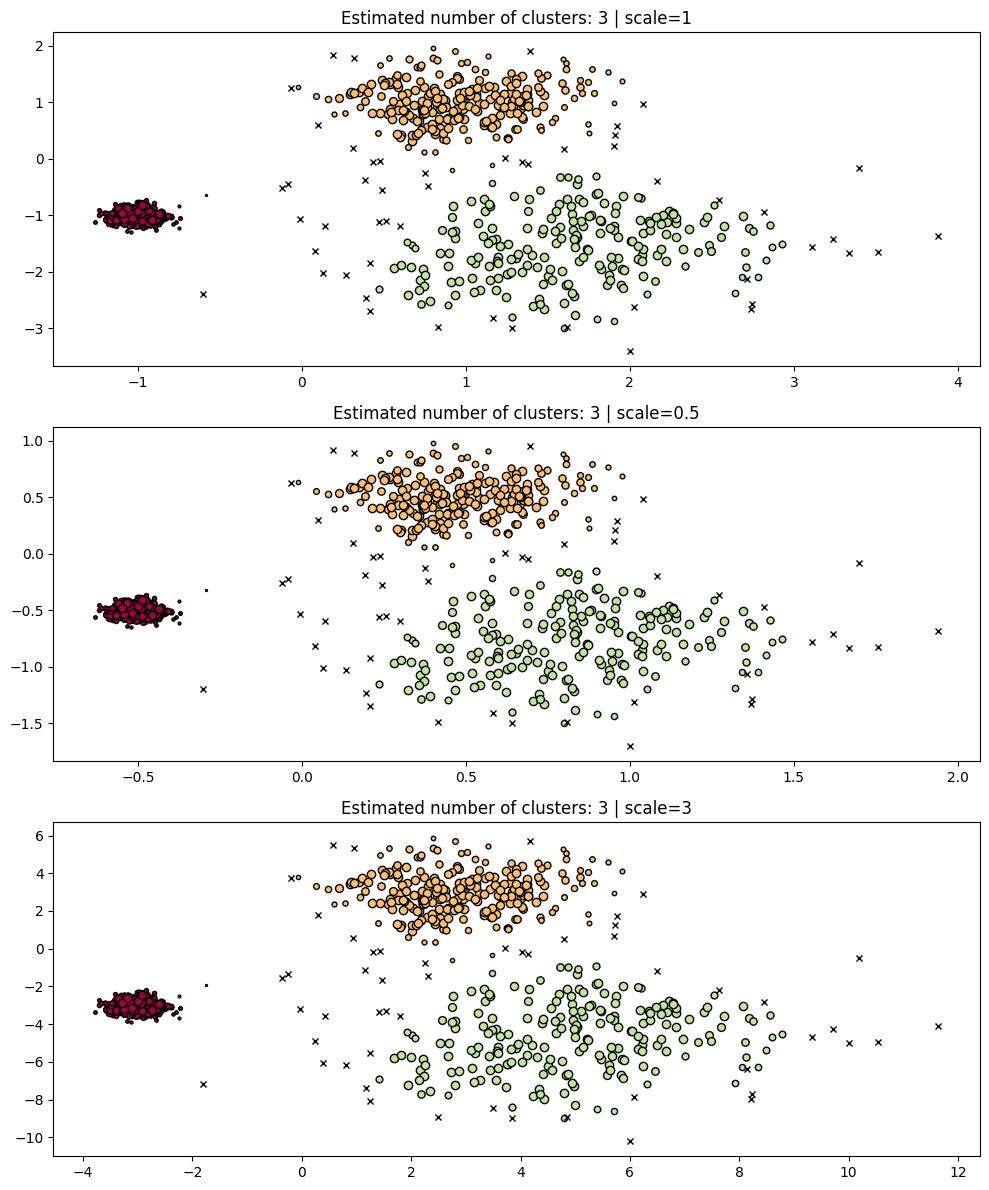

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

**HDBSCAN invarian terhadap skala**: pada ketiga skala, HDBSCAN menemukan hasil yang identik (3 cluster, tanpa noise) tanpa mengubah satu pun parameter. Hal ini karena HDBSCAN tidak bergantung pada satu nilai `eps` global, melainkan membangun hierarki kepadatan dari semua level.

## Langkah 6 - Multiscale Clustering

Buat dataset baru dengan kepadatan berbeda-beda (dua cluster padat kecil, dua cluster renggang besar).

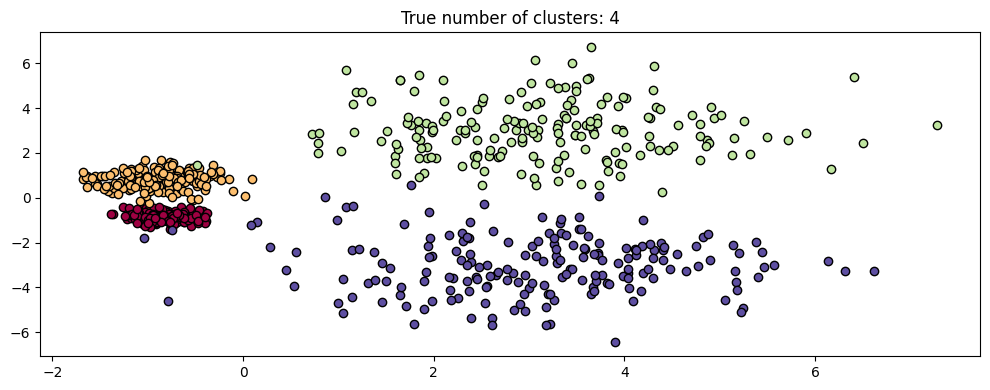

In [7]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)

Bandingkan DBSCAN dengan `eps` berbeda:

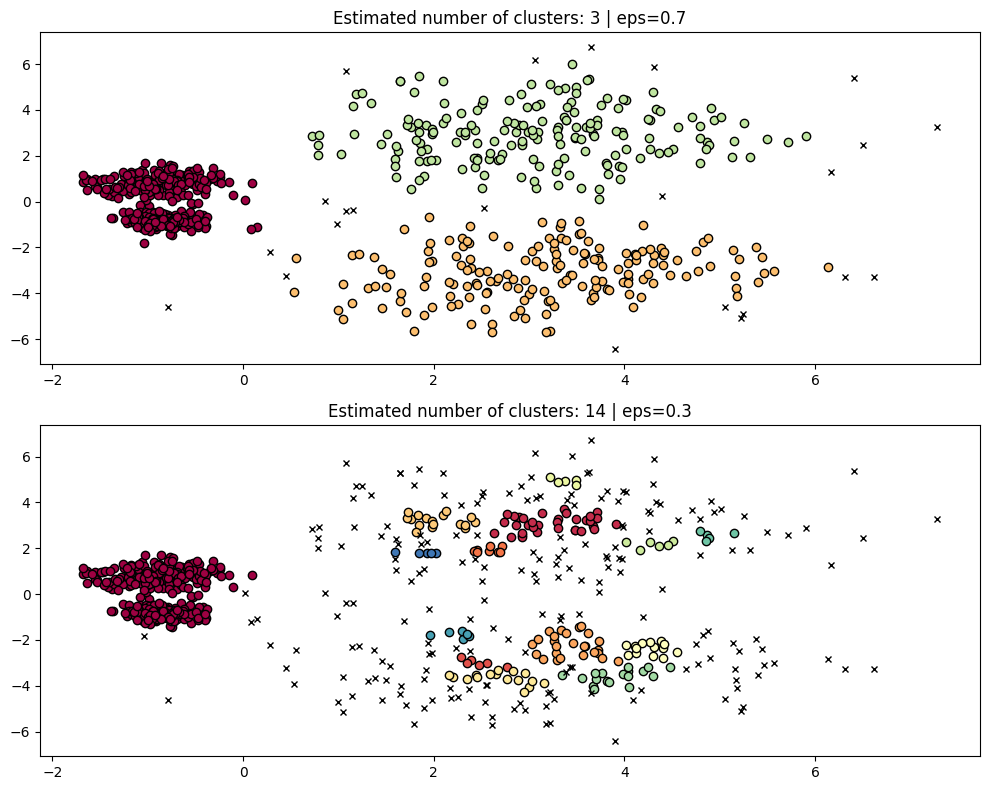

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])

Pada data multiscale ini DBSCAN menemui masalah: `eps=0.7` dapat menangkap cluster renggang namun menggabungkan dua cluster padat (plus banyak noise), sedangkan `eps=0.3` memisahkan cluster padat namun memecah cluster renggang menjadi banyak pecahan dengan noise melimpah. **Tidak ada satu nilai `eps` yang cocok untuk semua kepadatan.** Jalankan HDBSCAN:

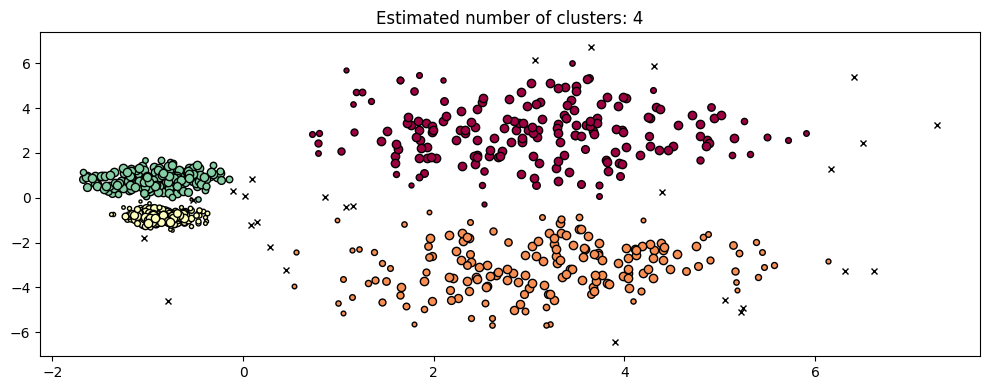

In [9]:
hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)

In [10]:
# Tampilkan cluster yang terbentuk
import collections
print('Distribusi label HDBSCAN:', dict(sorted(collections.Counter(hdb.labels_).items())))

Distribusi label HDBSCAN: {np.int64(-1): 27, np.int64(0): 181, np.int64(1): 168, np.int64(2): 192, np.int64(3): 182}


HDBSCAN dengan parameter default mampu menemukan **4 cluster** sekaligus pada data multiscale - cluster padat dan renggang sama-sama tertangkap, karena HDBSCAN mengekstrak cluster dari hierarki kepadatan pada berbagai level kepadatan (stabilitas cluster) tanpa perlu `eps` tunggal.

**Kesimpulan Lab 2:** HDBSCAN lebih robust daripada DBSCAN karena (1) invarian terhadap skala data, dan (2) mampu menangani cluster dengan kepadatan berbeda (*multiscale*) yang tidak dapat ditangani satu nilai `eps` pada DBSCAN. HDBSCAN juga menyediakan *membership strength* (probabilitas keanggotaan) serta deteksi noise secara otomatis.